Shape: (52560, 17)
Period: 2025-01-01 00:00:00 -> 2025-12-31 23:00:00
Locations: Anand Vihar, Connaught Place, Dwarka, IGI Airport, Okhla Phase III, Rohini
     date_ist time_ist     location      lat     lon  temp_c  humidity  pressure_mb  windspeed_kph condition_text  \
0  01-01-2025    00:00  Anand Vihar  28.6469  77.316     8.1       100        995.4            2.9   Mainly clear   
1  01-01-2025    01:00  Anand Vihar  28.6469  77.316     7.7       100        994.7            3.2       Overcast   
2  01-01-2025    02:00  Anand Vihar  28.6469  77.316     7.5       100        994.3            4.5       Overcast   
3  01-01-2025    03:00  Anand Vihar  28.6469  77.316     7.8        99        994.1            6.0       Overcast   
4  01-01-2025    04:00  Anand Vihar  28.6469  77.316     7.3       100        993.8            6.8       Overcast   

  description  aqi_index  pm2_5   pm10    co   no2           timestamp  
0  WMO Code 1        197  185.8  188.6  1907  56.7 2025-01-01 00:00:

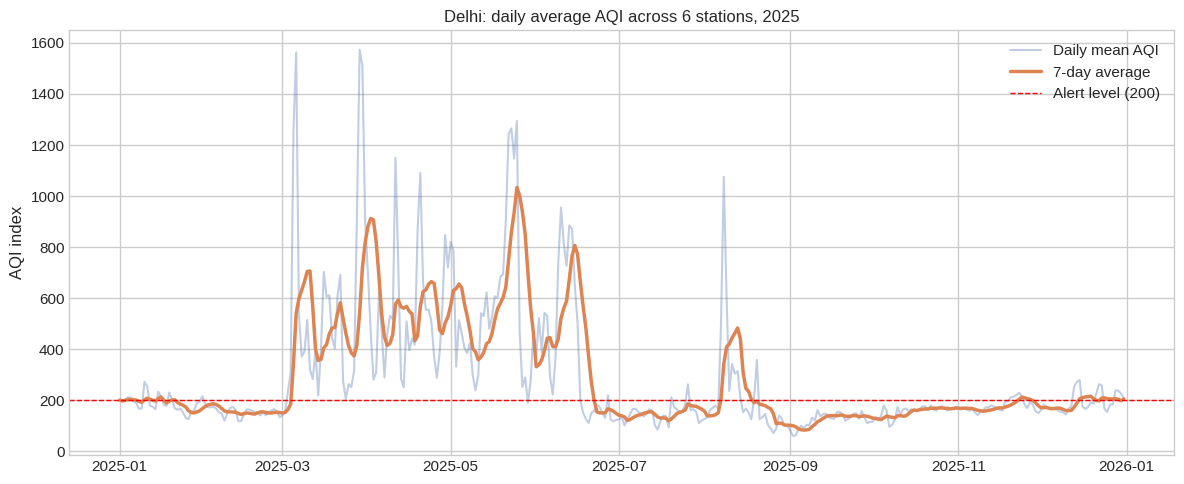

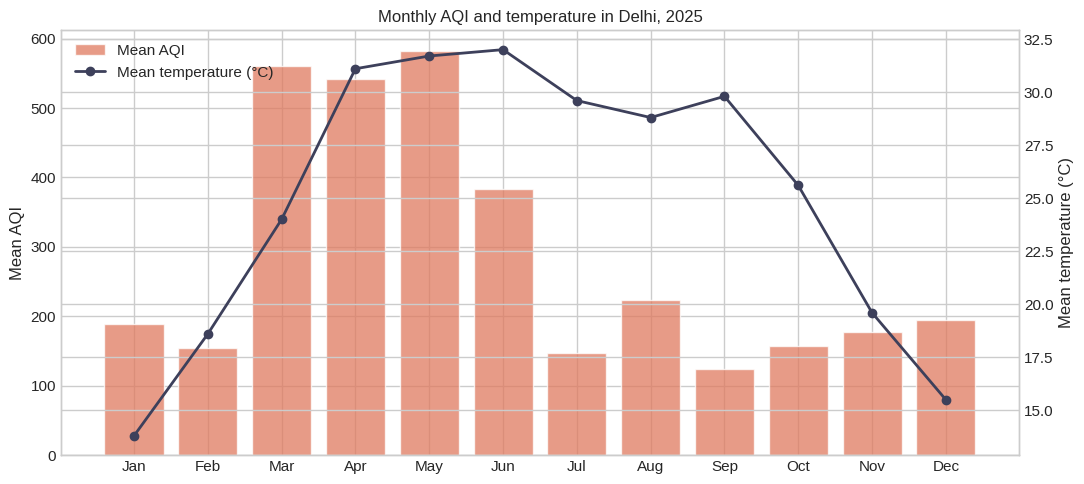

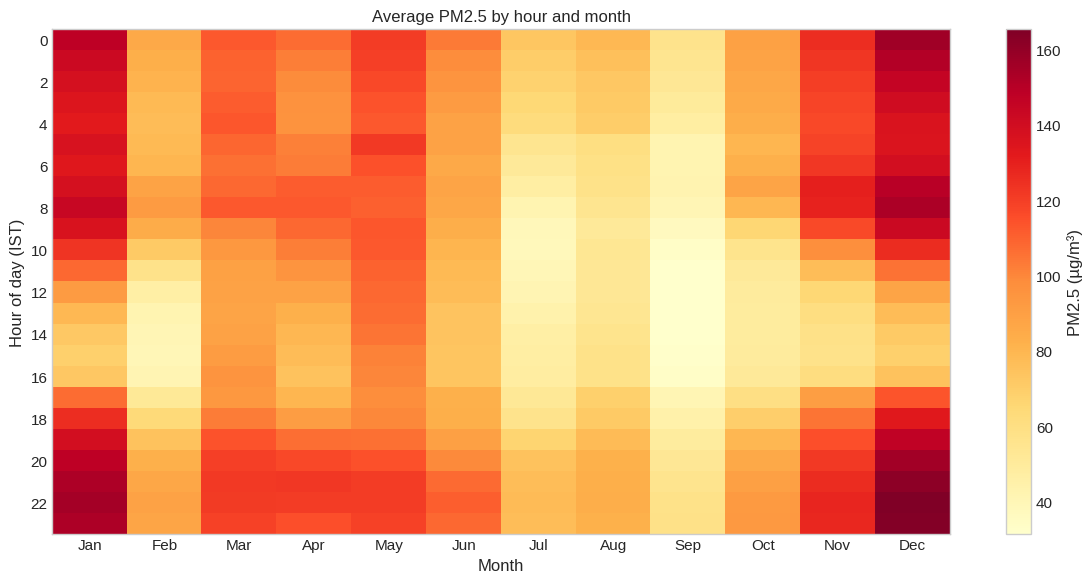

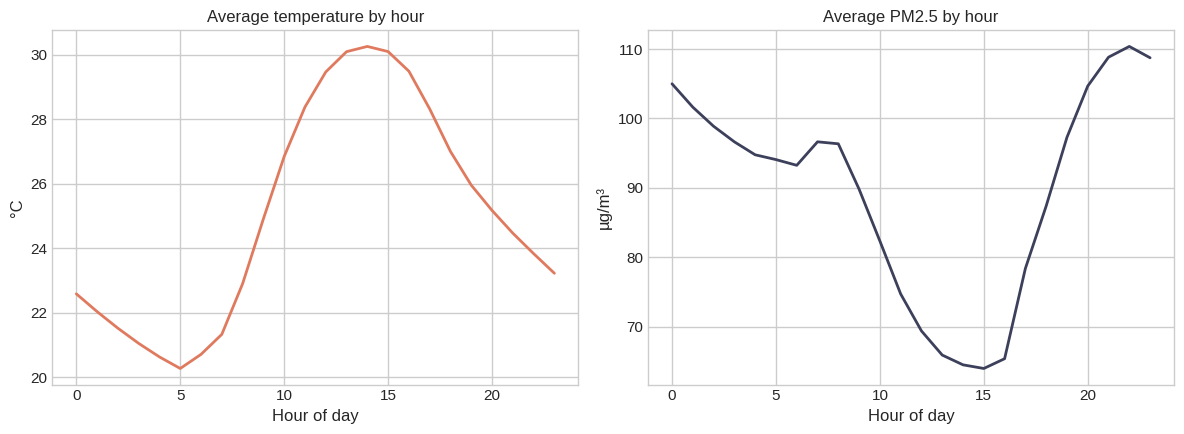

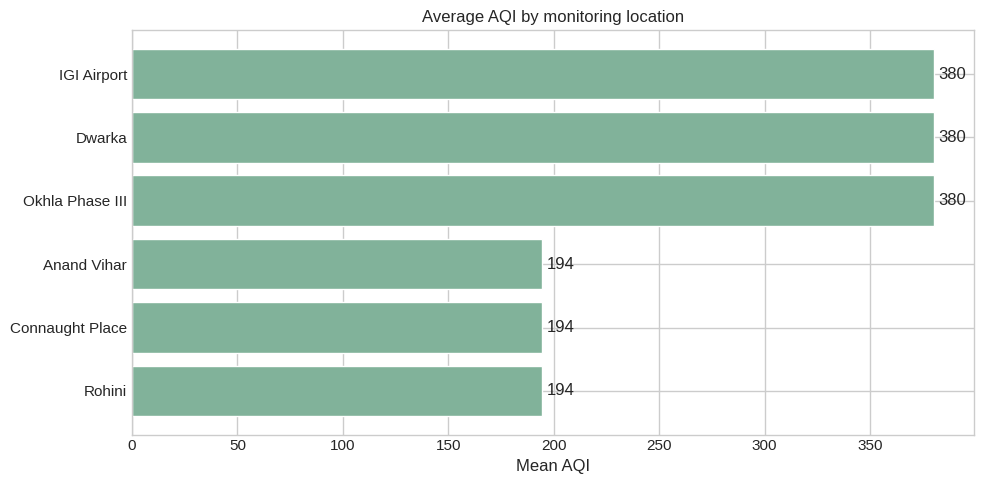

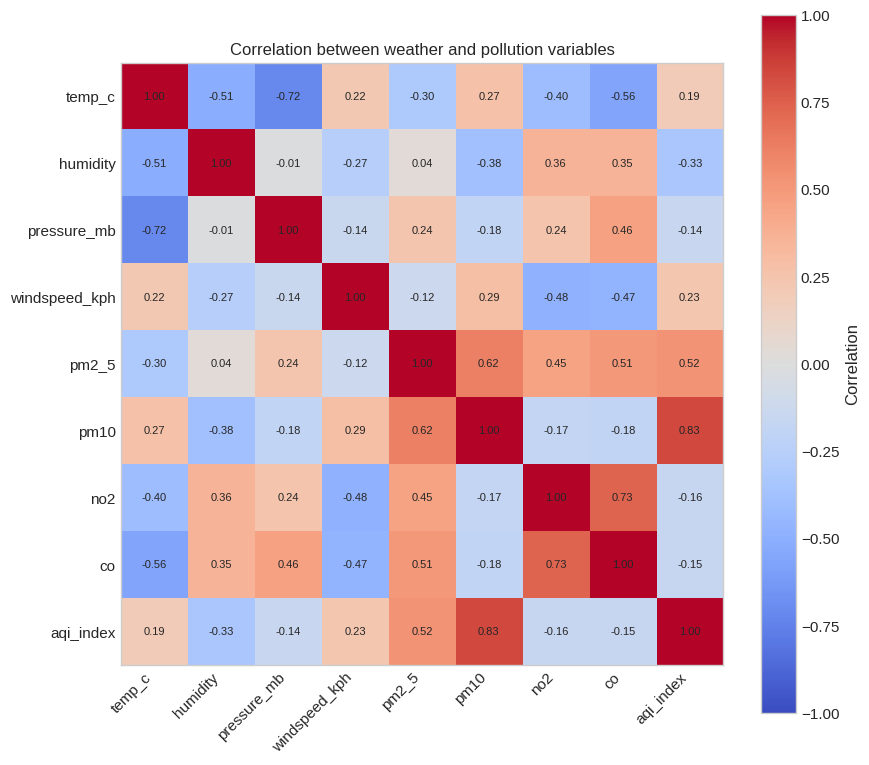

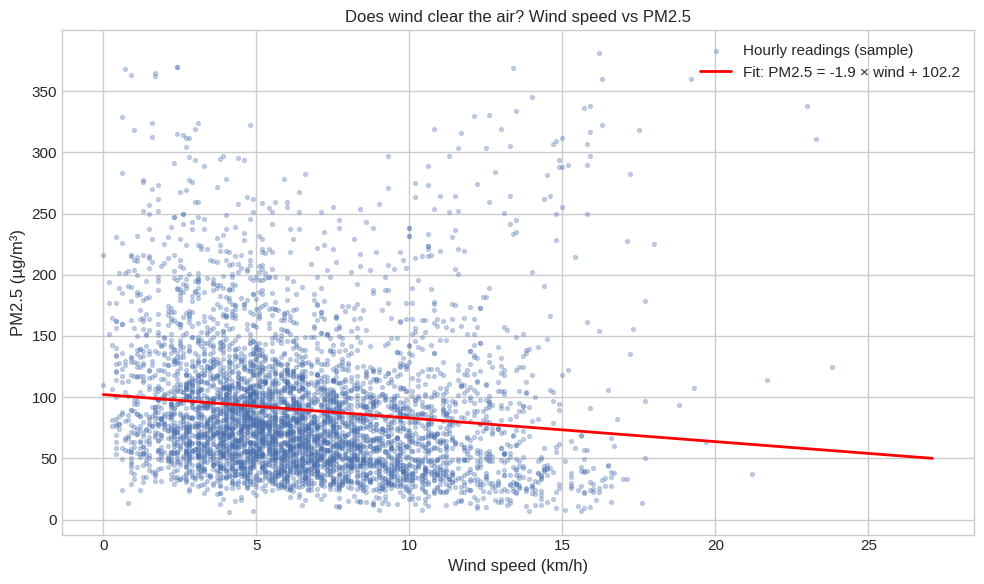

Worst month for AQI: May (mean 583)
Cleanest month for AQI: Sep (mean 124)
Worst station: IGI Airport (mean 380)
Cleanest station: Anand Vihar (mean 194)
Peak PM2.5 hour: 22:00
Share of hours above AQI 200: 31.7%

All tables and charts saved in: /content/analysis_output


In [ ]:
# %% [markdown]
# # Delhi Weather & AQI Analysis (2025)
#
# A step-by-step analysis of `delhi-weather-aqi-2025.csv` using pandas, NumPy and Matplotlib.
#
# How to run:
# - Jupyter / VS Code / Colab: each `# %%` block is one cell. Run them top to bottom.
# - Terminal: `python delhi_weather_aqi_analysis.py` (close each chart window to move on).
#
# Dataset: 52,560 rows = 365 days x 24 hours x 6 monitoring locations.

# %% STEP 0 — Setup
import calendar
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("delhi-weather-aqi-2025.csv")  # change this if the file is somewhere else
OUT_DIR = Path("analysis_output")               # tables and charts are saved here
AQI_ALERT = 200                                 # threshold used to count "bad air" hours

OUT_DIR.mkdir(exist_ok=True)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:  # older matplotlib versions use different style names; default style is fine
    pass


def save_and_show(fig, filename):
    """Save a chart to OUT_DIR and display it."""
    fig.tight_layout()
    fig.savefig(OUT_DIR / filename, dpi=150)
    plt.show()


# %% STEP 1 — Load the data
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find '{DATA_PATH}'. Python is looking in: {Path.cwd()}\n"
        "Either move the CSV into that folder, or set DATA_PATH to the full file path, "
        "for example Path(r'C:/Users/you/Downloads/delhi-weather-aqi-2025.csv')."
    )

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

# Tidy the column names: remove stray spaces and use lowercase, so " Date_IST" still matches "date_ist"
df.columns = df.columns.str.strip().str.lower()

REQUIRED_COLUMNS = [
    "date_ist", "time_ist", "location", "temp_c", "humidity", "pressure_mb",
    "windspeed_kph", "condition_text", "aqi_index", "pm2_5", "pm10", "co", "no2",
]
missing = [col for col in REQUIRED_COLUMNS if col not in df.columns]
if missing:
    raise ValueError(
        f"The file is missing these columns: {missing}\n"
        f"Columns found in the file: {list(df.columns)}"
    )

# date_ist is day-first (DD-MM-YYYY), so we give pandas the exact format
df["timestamp"] = pd.to_datetime(
    df["date_ist"] + " " + df["time_ist"], format="%d-%m-%Y %H:%M"
)

print("Shape:", df.shape)
print("Period:", df["timestamp"].min(), "->", df["timestamp"].max())
print("Locations:", ", ".join(sorted(df["location"].unique())))
print(df.head())

# %% STEP 2 — Data quality checks
print("Missing values per column:")
print(df.isna().sum())

print("\nDuplicate location-hour rows:", df.duplicated(subset=["location", "timestamp"]).sum())

print("\nRows per location:")
print(df["location"].value_counts())

print("\nWeather conditions:")
print(df["condition_text"].value_counts())

print(f"\nAQI range: {df['aqi_index'].min()} to {df['aqi_index'].max()}")
if df["aqi_index"].max() > 500:
    print("Note: standard AQI scales stop at 500, so check the data source's definition of aqi_index.")

# Do stations report the same pollution numbers? Identical series are not independent measurements.
pm25_by_station = df.pivot(index="timestamp", columns="location", values="pm2_5")
groups = {}
for station in pm25_by_station.columns:
    groups.setdefault(tuple(pm25_by_station[station]), []).append(station)

print("\nStations with identical hourly PM2.5 readings:")
for members in groups.values():
    if len(members) > 1:
        print("  -", ", ".join(members))

# %% STEP 3 — Add helper columns
df["date"] = df["timestamp"].dt.normalize()
df["month"] = df["timestamp"].dt.month
df["hour"] = df["timestamp"].dt.hour


def get_season(month):
    """Broad seasons used in Delhi."""
    if month in (12, 1, 2):
        return "Winter"
    if month in (3, 4, 5):
        return "Pre-monsoon"
    if month in (6, 7, 8, 9):
        return "Monsoon"
    return "Post-monsoon"


df["season"] = df["month"].map(get_season)
print(df[["timestamp", "month", "hour", "season"]].head())

# %% STEP 4 — Overall summary statistics (pandas + NumPy)
weather_cols = ["temp_c", "humidity", "pressure_mb", "windspeed_kph"]
pollution_cols = ["aqi_index", "pm2_5", "pm10", "no2", "co"]

summary = df[weather_cols + pollution_cols].agg(["mean", "median", "std", "min", "max"]).T.round(2)
print(summary)

# NumPy works directly on the underlying arrays
temp = df["temp_c"].to_numpy()
print("\nTemperature 5th / 50th / 95th percentile:", np.percentile(temp, [5, 50, 95]).round(1))

bad_air_share = (df["aqi_index"] > AQI_ALERT).mean()
print(f"Share of hours with AQI above {AQI_ALERT}: {bad_air_share:.1%}")

# %% STEP 5 — Monthly trends
monthly = df.groupby("month").agg(
    temp_mean=("temp_c", "mean"),
    temp_min=("temp_c", "min"),
    temp_max=("temp_c", "max"),
    humidity_mean=("humidity", "mean"),
    wind_mean=("windspeed_kph", "mean"),
    aqi_mean=("aqi_index", "mean"),
    pm25_mean=("pm2_5", "mean"),
).round(1)
monthly.index = monthly.index.map(lambda m: calendar.month_abbr[m])
monthly.index.name = "month"

print(monthly)
monthly.to_csv(OUT_DIR / "monthly_summary.csv")

# %% STEP 6 — Compare seasons and locations
# Caution: stations flagged in Step 2 share the same pollution readings,
# so their AQI/PM2.5 averages will tie. Read the location ranking with that in mind.
season_order = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]
seasonal = (
    df.groupby("season")[["temp_c", "aqi_index", "pm2_5"]]
    .mean()
    .loc[season_order]
    .round(1)
)
print(seasonal)

location_summary = (
    df.groupby("location")[["temp_c", "aqi_index", "pm2_5", "pm10"]]
    .mean()
    .sort_values("aqi_index", ascending=False)
    .round(1)
)
print("\nLocations ranked by mean AQI:")
print(location_summary)
location_summary.to_csv(OUT_DIR / "location_summary.csv")

# %% STEP 7 — Daily series with a 7-day rolling average
daily = df.groupby("date").agg(
    temp=("temp_c", "mean"),
    aqi=("aqi_index", "mean"),
    pm25=("pm2_5", "mean"),
)
daily["aqi_7day_avg"] = daily["aqi"].rolling(window=7, min_periods=1).mean()
daily.round(1).to_csv(OUT_DIR / "daily_summary.csv")
print(daily.head(10).round(1))

# %% STEP 8 — Time-of-day patterns
hourly = df.groupby("hour")[["temp_c", "pm2_5", "aqi_index"]].mean()
print("Peak PM2.5 hour:", f"{hourly['pm2_5'].idxmax():02d}:00")
print("Lowest PM2.5 hour:", f"{hourly['pm2_5'].idxmin():02d}:00")

# Hour x month grid of PM2.5 for the heatmap
heat = df.pivot_table(index="hour", columns="month", values="pm2_5", aggfunc="mean")

# %% STEP 9 — What moves with pollution? (correlations)
corr_cols = [
    "temp_c", "humidity", "pressure_mb", "windspeed_kph",
    "pm2_5", "pm10", "no2", "co", "aqi_index",
]
corr = df[corr_cols].corr()
print("Correlation with AQI (pandas):")
print(corr["aqi_index"].drop("aqi_index").sort_values().round(2))

# Same idea with NumPy, for one pair of variables
r_wind_pm = np.corrcoef(df["windspeed_kph"], df["pm2_5"])[0, 1]
print(f"\nNumPy check, wind speed vs PM2.5: r = {r_wind_pm:.2f}")

# %% STEP 10 — Simple linear regression: PM2.5 vs wind speed (NumPy)
x = df["windspeed_kph"].to_numpy()
y = df["pm2_5"].to_numpy()
slope, intercept = np.polyfit(x, y, deg=1)
print(f"Each extra 1 km/h of wind goes with {slope:+.2f} µg/m³ PM2.5")
print(f"Estimated PM2.5 with no wind: {intercept:.1f} µg/m³")
print(f"R-squared: {r_wind_pm ** 2:.3f}")

# %% STEP 11 — Weather condition vs air quality
by_condition = (
    df.groupby("condition_text")
    .agg(
        hours=("aqi_index", "size"),
        aqi_mean=("aqi_index", "mean"),
        pm25_mean=("pm2_5", "mean"),
    )
    .sort_values("aqi_mean", ascending=False)
    .round(1)
)
print(by_condition)
by_condition.to_csv(OUT_DIR / "condition_summary.csv")

# %% STEP 12 — Chart 1: daily AQI over the year
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily.index, daily["aqi"], alpha=0.35, label="Daily mean AQI")
ax.plot(daily.index, daily["aqi_7day_avg"], linewidth=2.5, label="7-day average")
ax.axhline(AQI_ALERT, color="red", linestyle="--", linewidth=1, label=f"Alert level ({AQI_ALERT})")
ax.set_title("Delhi: daily average AQI across 6 stations, 2025")
ax.set_ylabel("AQI index")
ax.legend()
save_and_show(fig, "01_daily_aqi.png")

# %% STEP 12 — Chart 2: monthly AQI vs temperature
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(monthly.index, monthly["aqi_mean"], color="#e07a5f", alpha=0.75, label="Mean AQI")
ax1.set_ylabel("Mean AQI")

ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["temp_mean"], color="#3d405b", marker="o",
         linewidth=2, label="Mean temperature (°C)")
ax2.set_ylabel("Mean temperature (°C)")

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
ax1.set_title("Monthly AQI and temperature in Delhi, 2025")
save_and_show(fig, "02_monthly_aqi_temp.png")

# %% STEP 12 — Chart 3: when is the air worst? (hour x month heatmap of PM2.5)
fig, ax = plt.subplots(figsize=(12, 6))
ax.grid(False)
image = ax.imshow(heat.to_numpy(), aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels([calendar.month_abbr[m] for m in heat.columns])
ax.set_yticks(range(0, 24, 2))
ax.set_xlabel("Month")
ax.set_ylabel("Hour of day (IST)")
ax.set_title("Average PM2.5 by hour and month")
fig.colorbar(image, ax=ax, label="PM2.5 (µg/m³)")
save_and_show(fig, "03_pm25_heatmap.png")

# %% STEP 12 — Chart 4: daily cycle of temperature and PM2.5
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(hourly.index, hourly["temp_c"], color="#e07a5f", linewidth=2)
ax1.set_title("Average temperature by hour")
ax1.set_xlabel("Hour of day")
ax1.set_ylabel("°C")

ax2.plot(hourly.index, hourly["pm2_5"], color="#3d405b", linewidth=2)
ax2.set_title("Average PM2.5 by hour")
ax2.set_xlabel("Hour of day")
ax2.set_ylabel("µg/m³")
save_and_show(fig, "04_hourly_profile.png")

# %% STEP 12 — Chart 5: which station is worst?
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(location_summary.index, location_summary["aqi_index"], color="#81b29a")
ax.invert_yaxis()
ax.set_xlabel("Mean AQI")
ax.set_title("Average AQI by monitoring location")
for i, value in enumerate(location_summary["aqi_index"]):
    ax.text(value + 2, i, f"{value:.0f}", va="center")
save_and_show(fig, "05_location_aqi.png")

# %% STEP 12 — Chart 6: correlation heatmap
fig, ax = plt.subplots(figsize=(9, 8))
ax.grid(False)
image = ax.imshow(corr.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)))
ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Correlation")
ax.set_title("Correlation between weather and pollution variables")
save_and_show(fig, "06_correlation_heatmap.png")

# %% STEP 12 — Chart 7: wind speed vs PM2.5 with the NumPy fit line
sample = df.sample(n=5000, random_state=42)  # a sample keeps the scatter readable
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(sample["windspeed_kph"], sample["pm2_5"], s=8, alpha=0.3,
           label="Hourly readings (sample)")
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, slope * xs + intercept, color="red", linewidth=2,
        label=f"Fit: PM2.5 = {slope:.1f} × wind + {intercept:.1f}")
ax.set_xlabel("Wind speed (km/h)")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Does wind clear the air? Wind speed vs PM2.5")
ax.legend()
save_and_show(fig, "07_wind_vs_pm25.png")

# %% STEP 13 — Key findings (computed from the data, not typed in by hand)
worst_month = monthly["aqi_mean"].idxmax()
best_month = monthly["aqi_mean"].idxmin()
worst_station = location_summary["aqi_index"].idxmax()
cleanest_station = location_summary["aqi_index"].idxmin()
peak_hour = hourly["pm2_5"].idxmax()

print(f"Worst month for AQI: {worst_month} (mean {monthly.loc[worst_month, 'aqi_mean']:.0f})")
print(f"Cleanest month for AQI: {best_month} (mean {monthly.loc[best_month, 'aqi_mean']:.0f})")
print(f"Worst station: {worst_station} (mean {location_summary.loc[worst_station, 'aqi_index']:.0f})")
print(f"Cleanest station: {cleanest_station} (mean {location_summary.loc[cleanest_station, 'aqi_index']:.0f})")
print(f"Peak PM2.5 hour: {peak_hour:02d}:00")
print(f"Share of hours above AQI {AQI_ALERT}: {bad_air_share:.1%}")
print(f"\nAll tables and charts saved in: {OUT_DIR.resolve()}")

Rows: 52,560 | Stations: 6 | Period: 01 Jan 2025 to 31 Dec 2025
Missing values: 0
Duplicate station-hours: 0
Hours per station: [np.int64(8760)]
pm25: identical across Anand Vihar, Connaught Place, Rohini; Dwarka, IGI Airport, Okhla Phase III
pm10: identical across Anand Vihar, Connaught Place, Rohini; Dwarka, IGI Airport, Okhla Phase III
no2: identical across Anand Vihar, Connaught Place, Rohini; Dwarka, IGI Airport, Okhla Phase III
aqi_index: identical across Anand Vihar, Connaught Place, Rohini; Dwarka, IGI Airport, Okhla Phase III
co: station-specific readings
temp_c: station-specific readings
                                            unit    mean  median     std      p5      p95     min      max  skewness
parameter                                                                                                           
Temperature                                   °C   25.02   26.50    7.62   11.40    36.30    5.70    43.80     -0.30
Dew point (derived)                         

Saving delhi-weather-aqi-2025.csv to delhi-weather-aqi-2025 (1).csv
52,560 rows | 6 stations | 01 Jan 2025 to 31 Dec 2025
Average weekly effect on PM2.5 (µg/m³):
date
Monday      -1.8
Tuesday     -4.4
Wednesday   -3.1
Thursday    -0.5
Friday       2.6
Saturday     2.0
Sunday       5.2


,Value
Finding,
Hottest month (mean temperature),Jun: 32.0 °C
Coldest month (mean temperature),Jan: 13.8 °C
"Share of rain and drizzle hours, June to September",82%
Months with fog,Dec
Most polluted month (mean PM2.5),Dec: 129 µg/m³
Cleanest month (mean PM2.5),Sep: 44 µg/m³
Station-days above the national PM2.5 limit,70.4%
Station-days above the WHO PM2.5 guideline,100.0%
Peak PM2.5 hour of day,22:00


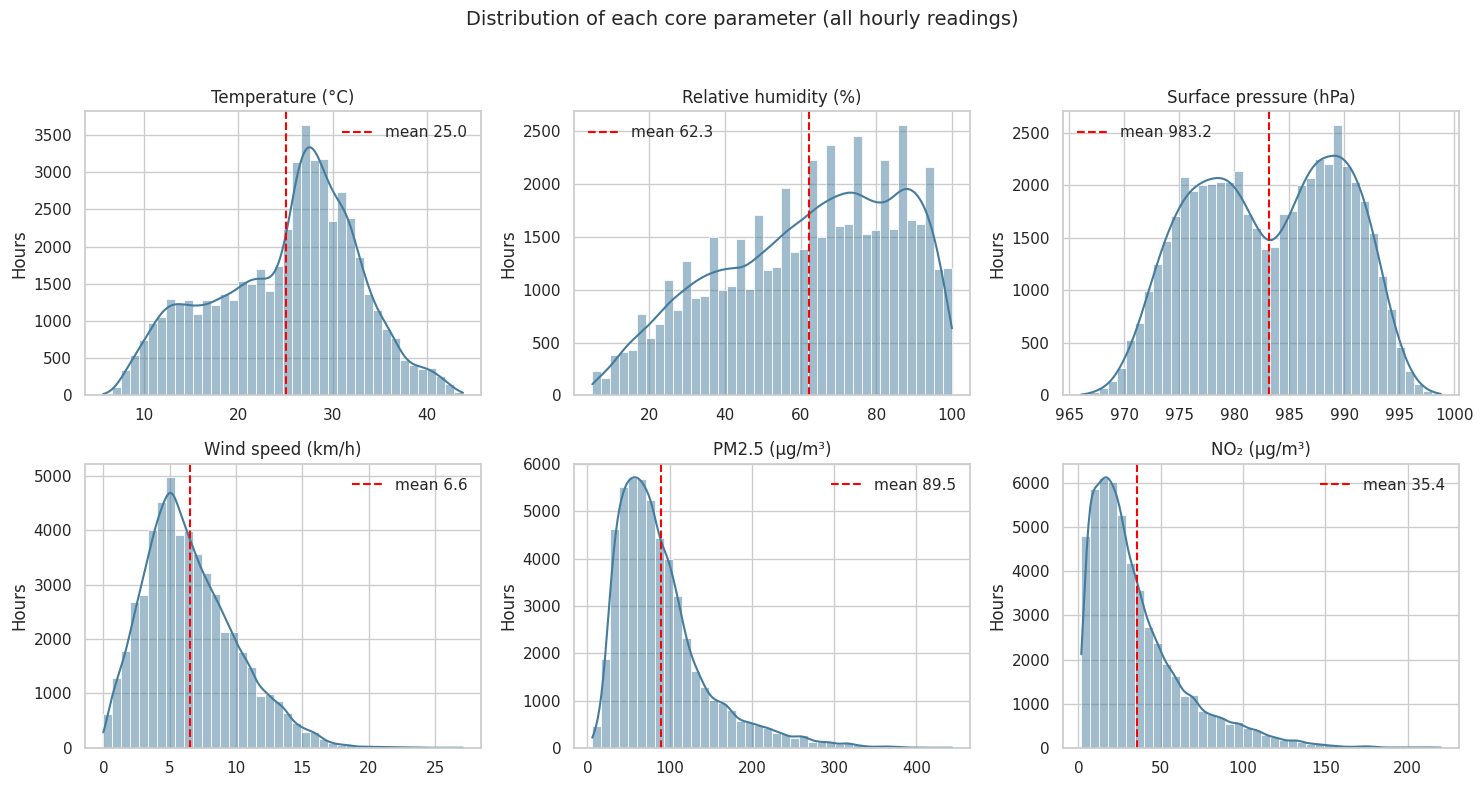

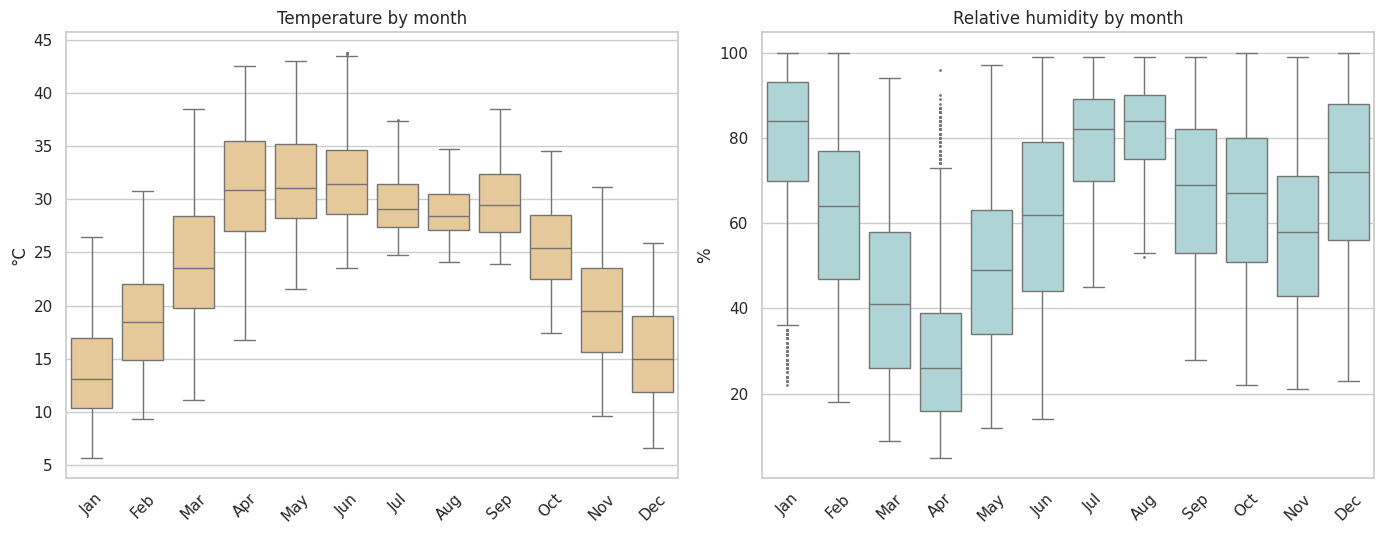

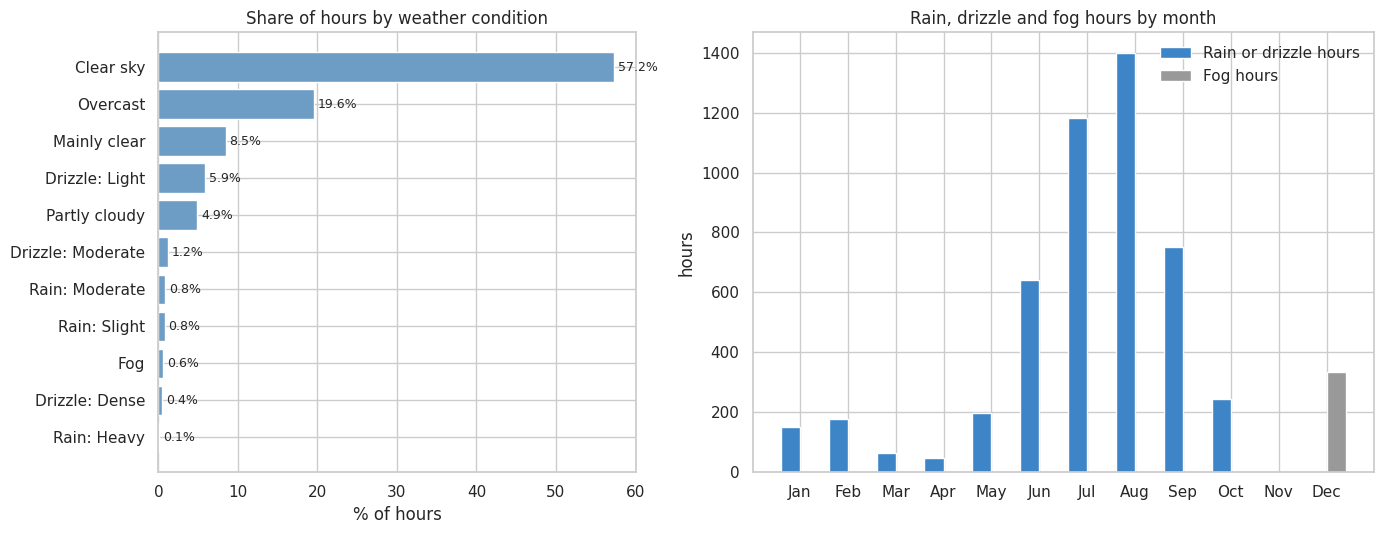

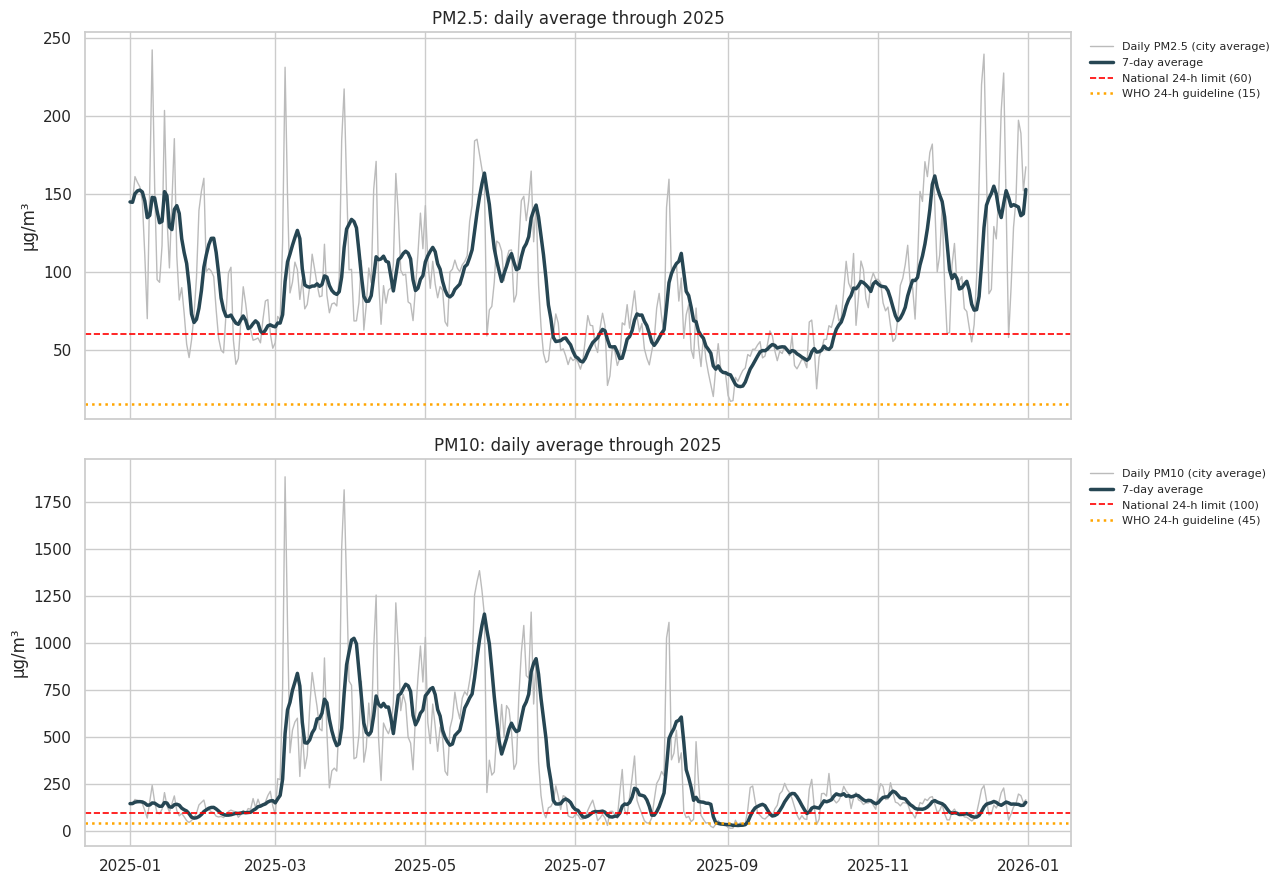

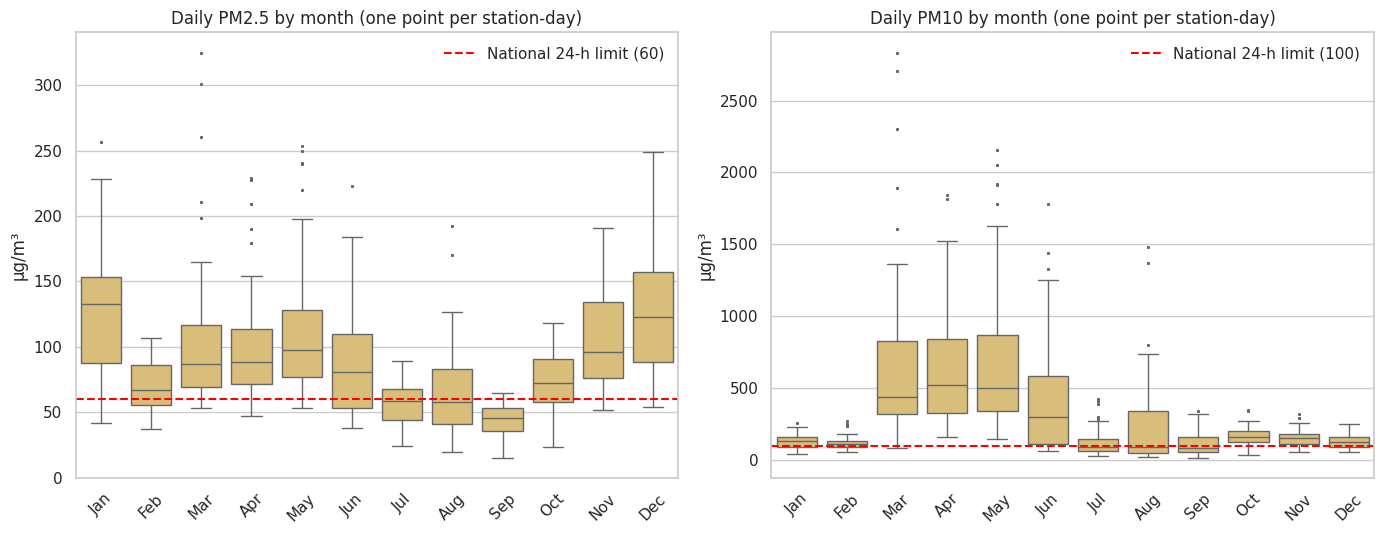

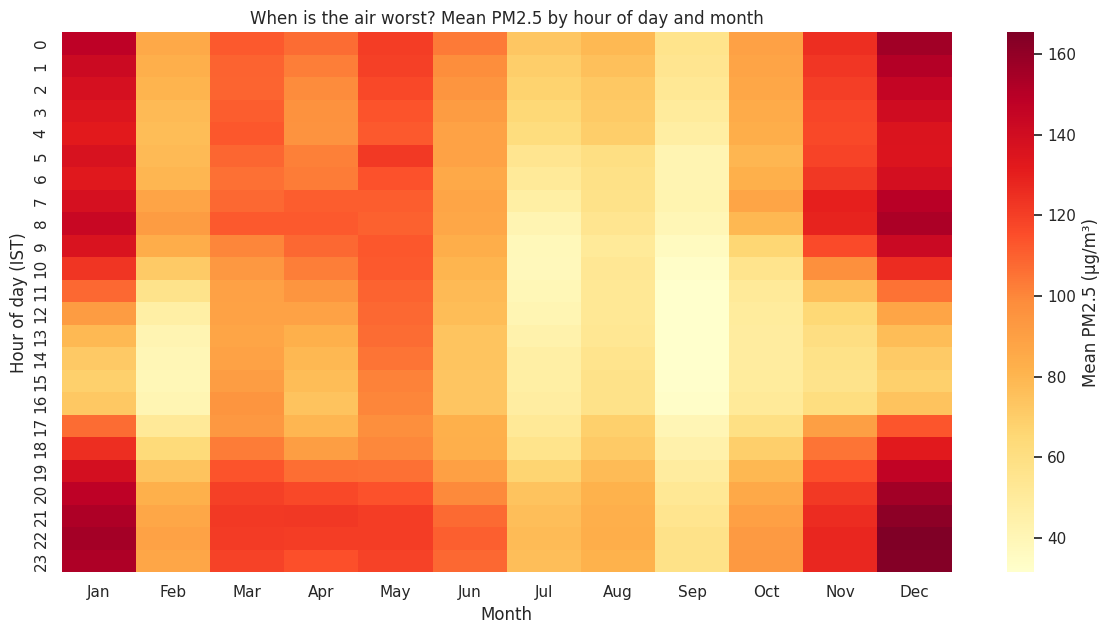

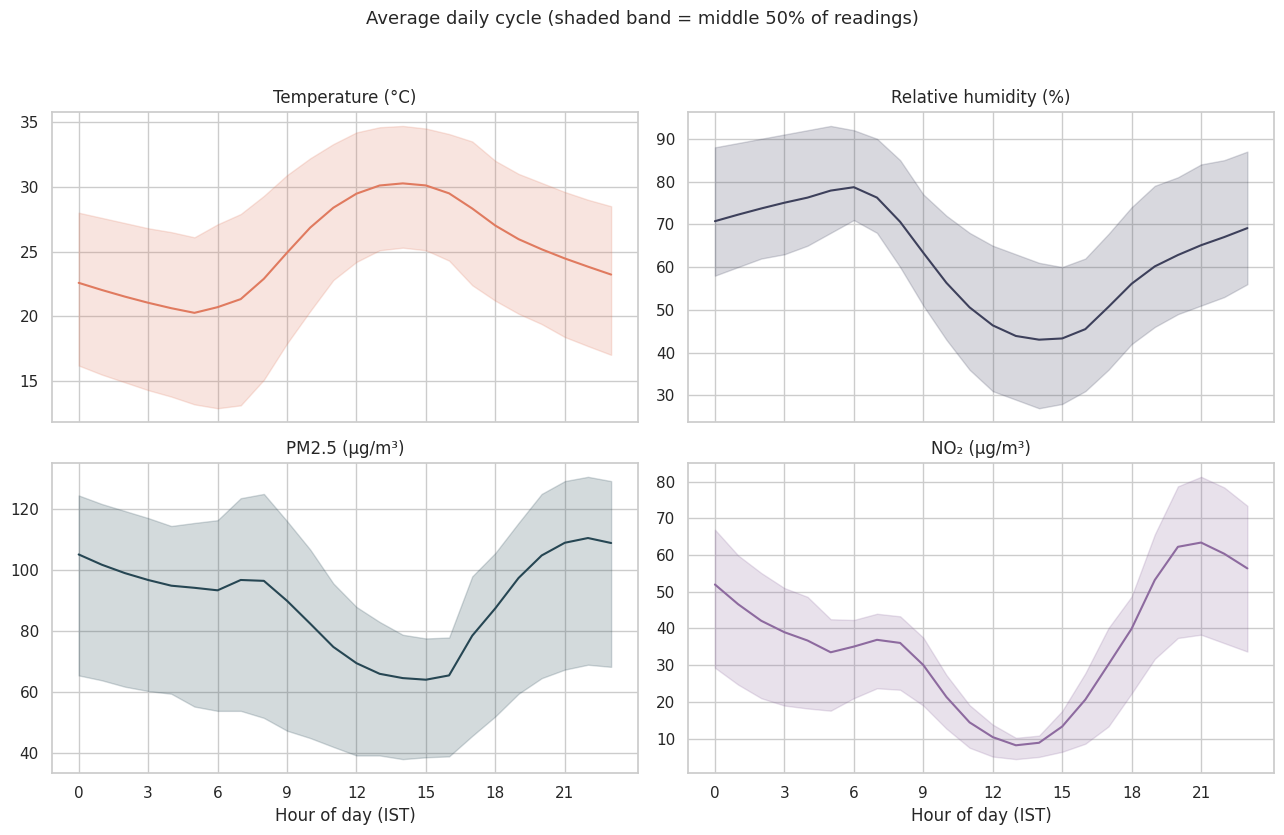

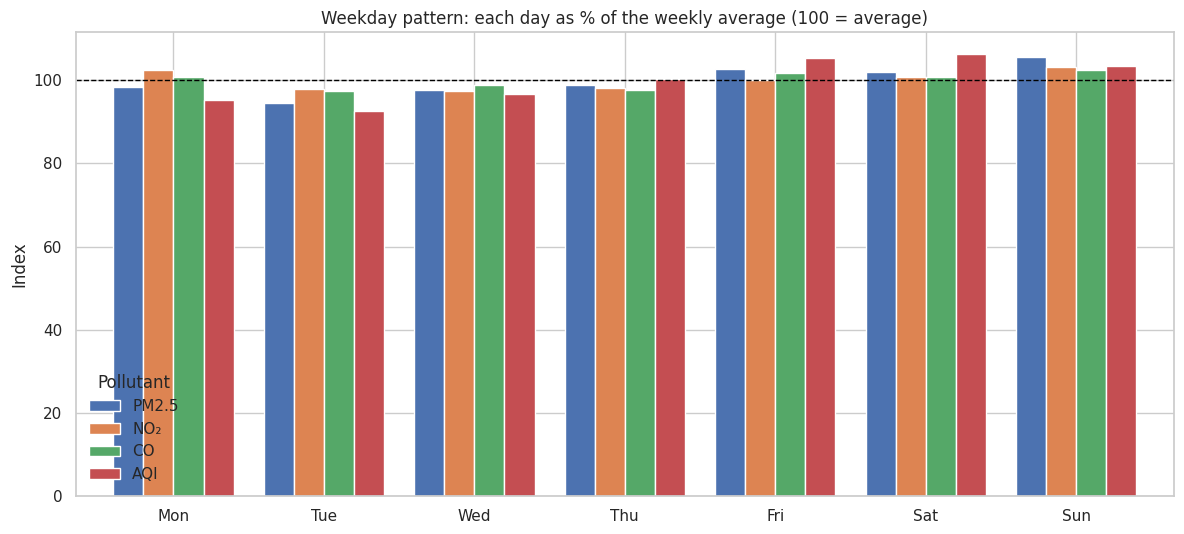

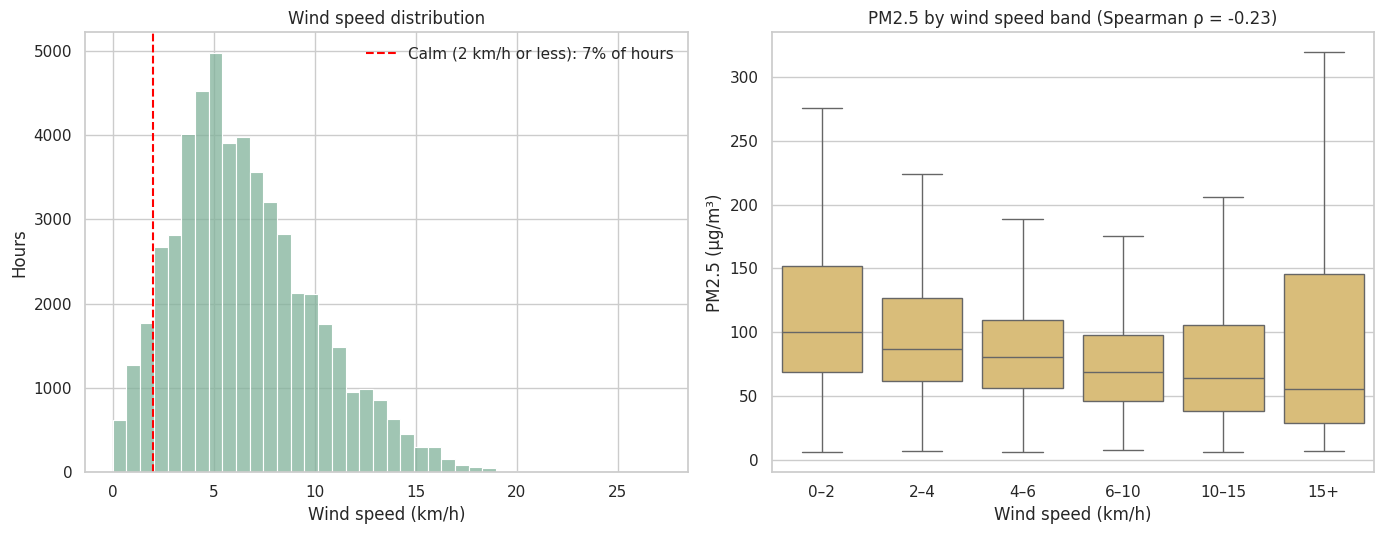

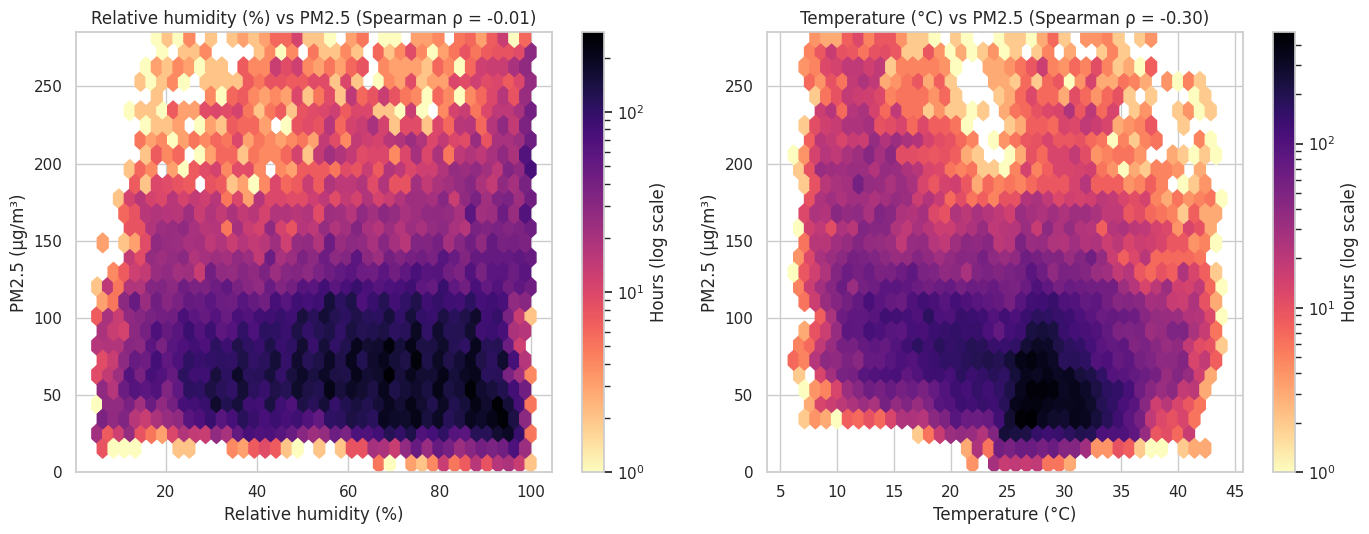

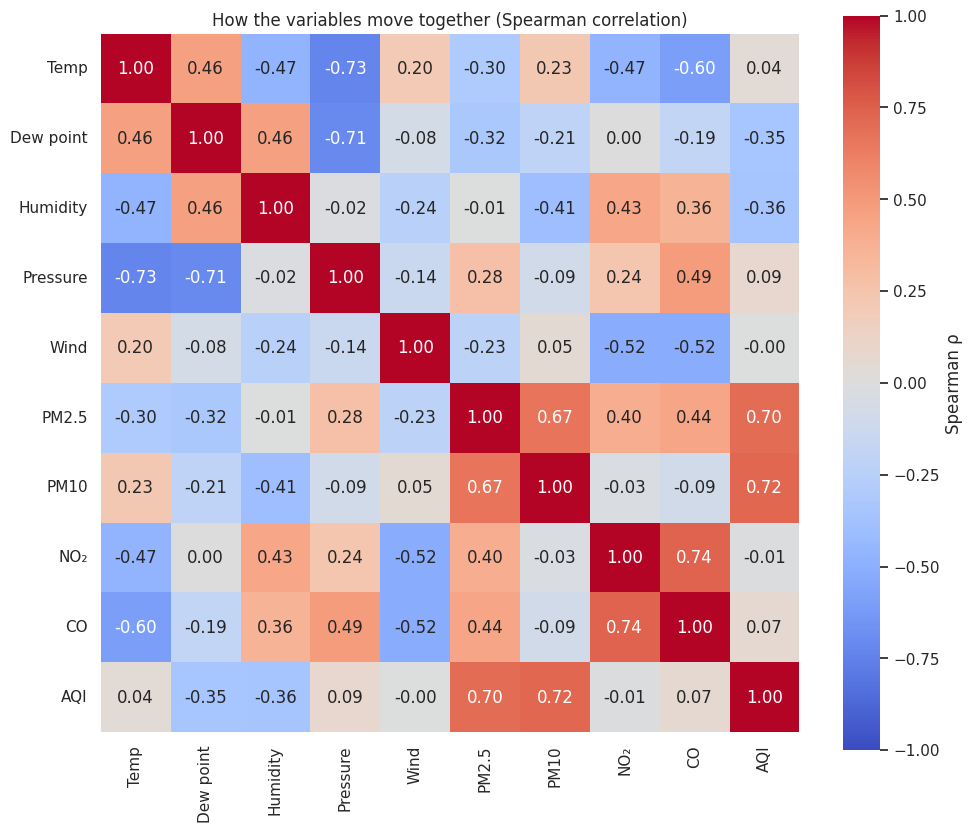

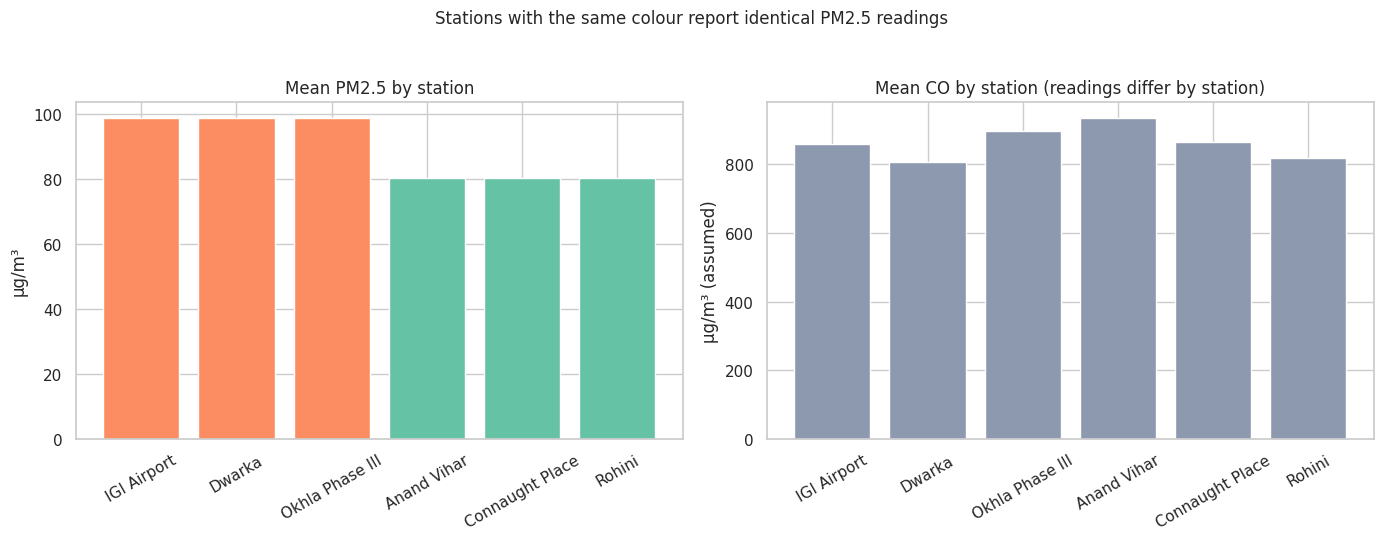

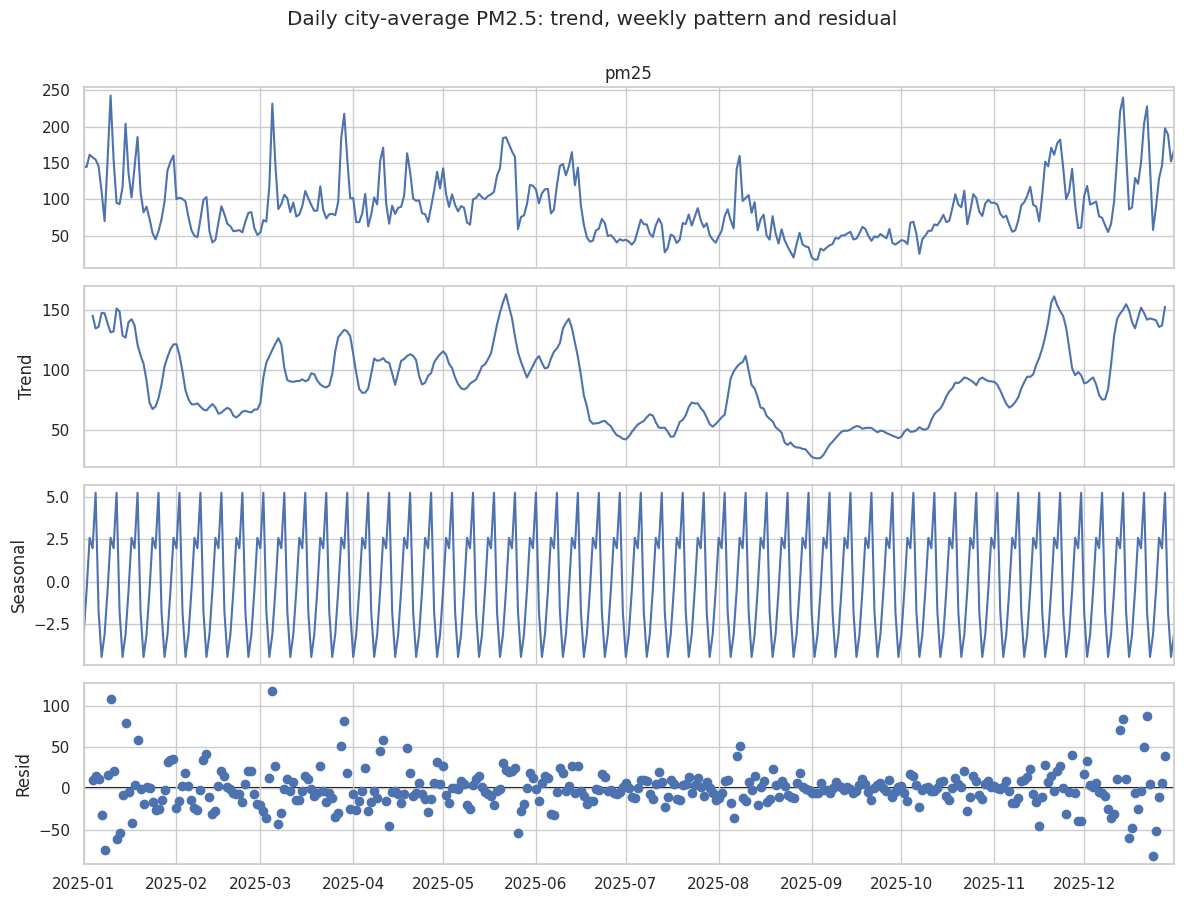

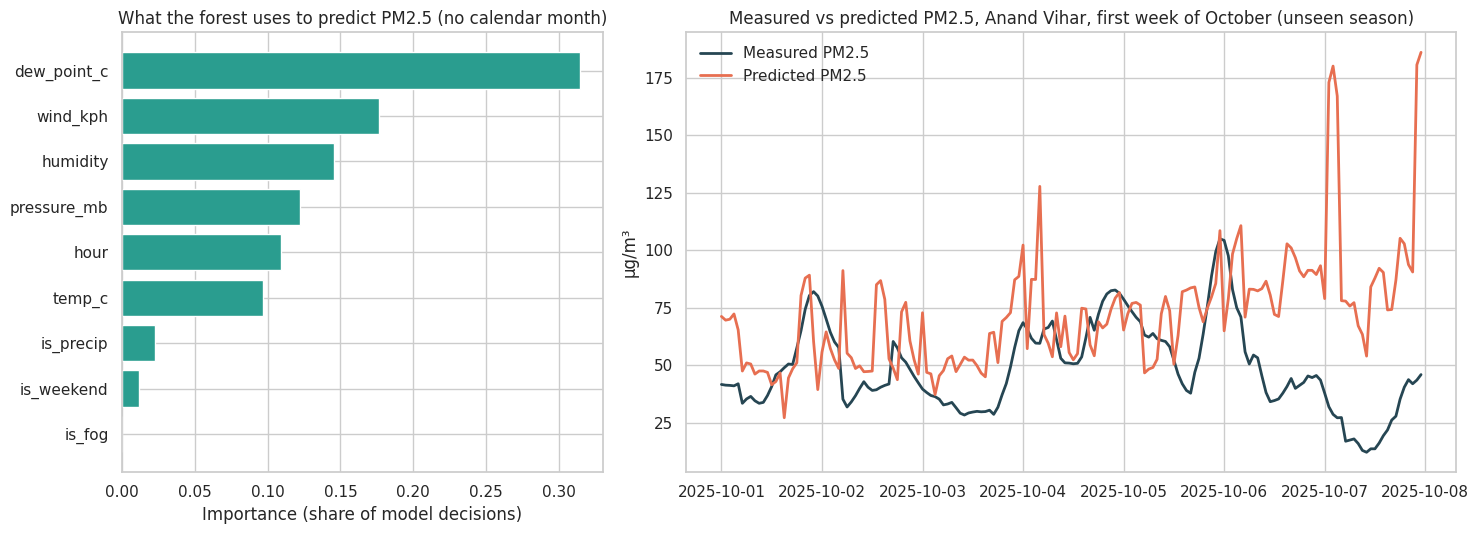

In [ ]:
%matplotlib inline
import calendar
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

try:
    from google.colab import files        # Colab: opens a file picker for the CSV
    uploaded = files.upload()
    DATA_PATH = Path(next(iter(uploaded), "delhi-weather-aqi-2025.csv"))
except ImportError:                       # not running in Colab (e.g. Jupyter on your computer)
    DATA_PATH = Path("delhi-weather-aqi-2025.csv")
NAAQS_PM25, NAAQS_PM10 = 60, 100                 # India's national 24-hour standards (µg/m³)
WHO_PM25, WHO_PM10 = 15, 45                      # WHO 2021 24-hour guideline values (µg/m³)
MONTHS = [calendar.month_abbr[m] for m in range(1, 13)]
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

#Cell 2: Load and clean the data#

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Could not find '{DATA_PATH}' in {Path.cwd()}. Re-run the upload cell and select the file.")

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df.columns = df.columns.str.strip().str.lower()
df = df.rename(columns={"windspeed_kph": "wind_kph", "pm2_5": "pm25"})
df["timestamp"] = pd.to_datetime(df["date_ist"] + " " + df["time_ist"], format="%d-%m-%Y %H:%M")

print(f"{len(df):,} rows | {df['location'].nunique()} stations | "
      f"{df['timestamp'].min():%d %b %Y} to {df['timestamp'].max():%d %b %Y}")
df.head()

#Cell 3: Time features and derived weather variables#

def get_season(month):
    """Broad seasons used in Delhi."""
    if month in (12, 1, 2):
        return "Winter"
    if month in (3, 4, 5):
        return "Pre-monsoon"
    if month in (6, 7, 8, 9):
        return "Monsoon"
    return "Post-monsoon"


df["date"] = df["timestamp"].dt.normalize()
df["month"] = df["timestamp"].dt.month
df["month_name"] = df["month"].map(lambda m: calendar.month_abbr[m])
df["hour"] = df["timestamp"].dt.hour
df["weekday"] = df["timestamp"].dt.day_name()
df["is_weekend"] = df["weekday"].isin(["Saturday", "Sunday"])
df["season"] = df["month"].map(get_season)

# Dew point (Magnus formula): the temperature the air must cool to before moisture condenses
a, b = 17.62, 243.12
gamma = np.log(df["humidity"].clip(lower=1) / 100) + a * df["temp_c"] / (b + df["temp_c"])
df["dew_point_c"] = b * gamma / (a - gamma)

df["is_precip"] = df["condition_text"].str.contains("Rain|Drizzle")
df["is_fog"] = df["condition_text"].eq("Fog")
df[["timestamp", "month_name", "hour", "weekday", "season", "dew_point_c", "is_precip", "is_fog"]].head()

#Cell 4: Data quality checks#
pd.Series({
    "Rows": f"{len(df):,}",
    "Missing values": int(df.isna().sum().sum()),
    "Duplicate station-hours": int(df.duplicated(["location", "timestamp"]).sum()),
    "Hours per station": str(sorted(df.groupby("location").size().unique().tolist())),
}, name="value").to_frame()

#Cell 5: Stations with identical readings#
def identical_station_groups(column):
    """Groups of stations whose hourly readings are exactly the same."""
    wide = df.pivot(index="timestamp", columns="location", values=column)
    groups = {}
    for station in wide.columns:
        groups.setdefault(tuple(wide[station]), []).append(station)
    return [members for members in groups.values() if len(members) > 1]


shared_groups = {col: identical_station_groups(col)
                 for col in ["pm25", "pm10", "no2", "aqi_index", "co", "temp_c"]}
pd.DataFrame({
    "variable": list(shared_groups),
    "stations with identical readings": [
        "; ".join(" = ".join(group) for group in groups) or "none (station-specific)"
        for groups in shared_groups.values()
    ],
}).set_index("variable")

#Cell 6: Parameter inventory#
PARAMETERS = {
    "temp_c": ("Temperature", "°C"),
    "dew_point_c": ("Dew point (derived)", "°C"),
    "humidity": ("Relative humidity", "%"),
    "pressure_mb": ("Surface pressure", "hPa"),
    "wind_kph": ("Wind speed", "km/h"),
    "pm25": ("PM2.5", "µg/m³"),
    "pm10": ("PM10", "µg/m³"),
    "no2": ("Nitrogen dioxide (NO₂)", "µg/m³ (assumed)"),
    "co": ("Carbon monoxide (CO)", "µg/m³ (assumed)"),
    "aqi_index": ("AQI index", "index (scale unverified)"),
}

rows = []
for col, (label, unit) in PARAMETERS.items():
    s = df[col]
    rows.append({
        "parameter": label, "unit": unit,
        "mean": s.mean(), "median": s.median(), "std": s.std(),
        "p5": s.quantile(0.05), "p95": s.quantile(0.95),
        "min": s.min(), "max": s.max(), "skewness": stats.skew(s),
    })
inventory = pd.DataFrame(rows).set_index("parameter").round(2)
inventory

#Cell 7: Distributions of core parameters#
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
panels = [("temp_c", "Temperature (°C)"), ("humidity", "Relative humidity (%)"),
          ("pressure_mb", "Surface pressure (hPa)"), ("wind_kph", "Wind speed (km/h)"),
          ("pm25", "PM2.5 (µg/m³)"), ("no2", "NO₂ (µg/m³)")]
for ax, (col, label) in zip(axes.ravel(), panels):
    sns.histplot(df[col], bins=40, kde=True, color="#457b9d", ax=ax)
    ax.axvline(df[col].mean(), color="red", ls="--", label=f"mean {df[col].mean():.1f}")
    ax.set(title=label, xlabel="", ylabel="Hours")
    ax.legend()
fig.suptitle("Distribution of each core parameter (all hourly readings)", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.95))

#Cell 8: Temperature and humidity by month#
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
sns.boxplot(data=df, x="month_name", y="temp_c", order=MONTHS, color="#f2cc8f", fliersize=1, ax=ax1)
ax1.set(title="Temperature by month", xlabel="", ylabel="°C")
sns.boxplot(data=df, x="month_name", y="humidity", order=MONTHS, color="#a8dadc", fliersize=1, ax=ax2)
ax2.set(title="Relative humidity by month", xlabel="", ylabel="%")
for ax in (ax1, ax2):
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
cond_share = df["condition_text"].value_counts(normalize=True).mul(100).sort_values()
precip_fog = df.groupby("month")[["is_precip", "is_fog"]].sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})
ax1.barh(cond_share.index, cond_share.values, color="#6d9dc5")
ax1.set(title="Share of hours by weather condition", xlabel="% of hours")
for i, value in enumerate(cond_share.values):
    ax1.text(value + 0.5, i, f"{value:.1f}%", va="center", fontsize=9)

x = np.arange(12)
width = 0.4
ax2.bar(x - width / 2, precip_fog["is_precip"], width, label="Rain or drizzle hours", color="#3d85c6")
ax2.bar(x + width / 2, precip_fog["is_fog"], width, label="Fog hours", color="#999999")
ax2.set_xticks(x)
ax2.set_xticklabels(MONTHS)
ax2.set(title="Rain, drizzle and fog hours by month", ylabel="hours")
ax2.legend()
fig.tight_layout()

daily_city = df.groupby("date")[["pm25", "pm10"]].mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
for ax, col, national, who, label in [
    (ax1, "pm25", NAAQS_PM25, WHO_PM25, "PM2.5"),
    (ax2, "pm10", NAAQS_PM10, WHO_PM10, "PM10"),
]:
    ax.plot(daily_city.index, daily_city[col], color="#bbbbbb", lw=1, label=f"Daily {label} (city average)")
    ax.plot(daily_city.index, daily_city[col].rolling(7, min_periods=1).mean(),
            color="#264653", lw=2.5, label="7-day average")
    ax.axhline(national, color="red", ls="--", lw=1.2, label=f"National 24-h limit ({national})")
    ax.axhline(who, color="orange", ls=":", lw=1.8, label=f"WHO 24-h guideline ({who})")
    ax.set(title=f"{label}: daily average through 2025", ylabel="µg/m³")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
fig.tight_layout()

daily_station = df.groupby(["location", "date"]).agg(pm25=("pm25", "mean"), pm10=("pm10", "mean")).reset_index()
daily_station["month_name"] = daily_station["date"].dt.month.map(lambda m: calendar.month_abbr[m])

exceedance = pd.DataFrame({
    "limit (µg/m³)": [NAAQS_PM25, WHO_PM25, NAAQS_PM10],
    "share of station-days above limit": [
        (daily_station["pm25"] > NAAQS_PM25).mean(),
        (daily_station["pm25"] > WHO_PM25).mean(),
        (daily_station["pm10"] > NAAQS_PM10).mean(),
    ],
}, index=["PM2.5, national 24-h limit", "PM2.5, WHO 24-h guideline", "PM10, national 24-h limit"])
exceedance["share of station-days above limit"] = exceedance["share of station-days above limit"].map("{:.1%}".format)
exceedance

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, col, limit, label in [(ax1, "pm25", NAAQS_PM25, "PM2.5"), (ax2, "pm10", NAAQS_PM10, "PM10")]:
    sns.boxplot(data=daily_station, x="month_name", y=col, order=MONTHS, color="#e9c46a", fliersize=1, ax=ax)
    ax.axhline(limit, color="red", ls="--", label=f"National 24-h limit ({limit})")
    ax.set(title=f"Daily {label} by month (one point per station-day)", xlabel="", ylabel="µg/m³")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
fig.tight_layout()

heat = df.pivot_table(index="hour", columns="month", values="pm25", aggfunc="mean")
heat.columns = MONTHS

fig, ax = plt.subplots(figsize=(12, 6.5))
sns.heatmap(heat, cmap="YlOrRd", cbar_kws={"label": "Mean PM2.5 (µg/m³)"}, ax=ax)
ax.set(title="When is the air worst? Mean PM2.5 by hour of day and month",
       xlabel="Month", ylabel="Hour of day (IST)")
fig.tight_layout()

panels = [("temp_c", "Temperature (°C)", "#e07a5f"), ("humidity", "Relative humidity (%)", "#3d405b"),
          ("pm25", "PM2.5 (µg/m³)", "#264653"), ("no2", "NO₂ (µg/m³)", "#8d6a9f")]
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True)
for ax, (col, label, color) in zip(axes.ravel(), panels):
    sns.lineplot(data=df, x="hour", y=col, color=color, errorbar=("pi", 50), ax=ax)
    ax.set(title=label, xlabel="Hour of day (IST)", ylabel="")
    ax.set_xticks(range(0, 24, 3))
fig.suptitle("Average daily cycle (shaded band = middle 50% of readings)", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))

weekday_means = df.groupby("weekday")[["pm25", "no2", "co", "aqi_index"]].mean().reindex(WEEKDAYS)
weekday_index = (weekday_means / weekday_means.mean() * 100).rename(
    index=lambda day: day[:3],
    columns={"pm25": "PM2.5", "no2": "NO₂", "co": "CO", "aqi_index": "AQI"},
)

fig, ax = plt.subplots(figsize=(12, 5.5))
weekday_index.plot(kind="bar", ax=ax, width=0.8, rot=0)
ax.axhline(100, color="black", ls="--", lw=1)
ax.set(title="Weekday pattern: each day as % of the weekly average (100 = average)", xlabel="", ylabel="Index")
ax.legend(title="Pollutant")
fig.tight_layout()

calm_share = (df["wind_kph"] <= 2).mean()
wind_labels = ["0–2", "2–4", "4–6", "6–10", "10–15", "15+"]
df["wind_band"] = pd.cut(df["wind_kph"], bins=[0, 2, 4, 6, 10, 15, np.inf],
                         labels=wind_labels, include_lowest=True)
rho_wind = df["wind_kph"].corr(df["pm25"], method="spearman")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
sns.histplot(df["wind_kph"], bins=40, color="#81b29a", ax=ax1)
ax1.axvline(2, color="red", ls="--", label=f"Calm (2 km/h or less): {calm_share:.0%} of hours")
ax1.set(title="Wind speed distribution", xlabel="Wind speed (km/h)", ylabel="Hours")
ax1.legend()
sns.boxplot(data=df, x="wind_band", y="pm25", order=wind_labels, color="#e9c46a", showfliers=False, ax=ax2)
ax2.set(title=f"PM2.5 by wind speed band (Spearman ρ = {rho_wind:.2f})",
        xlabel="Wind speed (km/h)", ylabel="PM2.5 (µg/m³)")
fig.tight_layout()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, col, label in [(ax1, "humidity", "Relative humidity (%)"), (ax2, "temp_c", "Temperature (°C)")]:
    hb = ax.hexbin(df[col], df["pm25"], gridsize=40, mincnt=1, bins="log", cmap="magma_r")
    rho = df[col].corr(df["pm25"], method="spearman")
    ax.set(title=f"{label} vs PM2.5 (Spearman ρ = {rho:.2f})", xlabel=label,
           ylabel="PM2.5 (µg/m³)", ylim=(0, df["pm25"].quantile(0.99)))
    fig.colorbar(hb, ax=ax, label="Hours (log scale)")
fig.tight_layout()

corr_vars = ["temp_c", "dew_point_c", "humidity", "pressure_mb", "wind_kph",
             "pm25", "pm10", "no2", "co", "aqi_index"]
spearman = df[corr_vars].corr(method="spearman")
short_names = {"temp_c": "Temp", "dew_point_c": "Dew point", "humidity": "Humidity", "pressure_mb": "Pressure",
               "wind_kph": "Wind", "pm25": "PM2.5", "pm10": "PM10", "no2": "NO₂", "co": "CO", "aqi_index": "AQI"}

fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(spearman.rename(index=short_names, columns=short_names), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar_kws={"label": "Spearman ρ"}, ax=ax)
ax.set_title("How the variables move together (Spearman correlation)")
fig.tight_layout()

station = df.groupby("location")[["temp_c", "pm25", "no2", "co"]].mean().sort_values("pm25", ascending=False)

pm25_groups = shared_groups["pm25"]
cluster_of = {s: i for i, group in enumerate(pm25_groups) for s in group}
palette = sns.color_palette("Set2", n_colors=len(pm25_groups) + 1)
bar_colors = [palette[cluster_of.get(s, len(pm25_groups))] for s in station.index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
ax1.bar(station.index, station["pm25"], color=bar_colors)
ax1.set(title="Mean PM2.5 by station", ylabel="µg/m³")
ax2.bar(station.index, station["co"], color="#8d99ae")
ax2.set(title="Mean CO by station (readings differ by station)", ylabel="µg/m³ (assumed)")
for ax in (ax1, ax2):
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Stations with the same colour report identical PM2.5 readings", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))

daily_pm = df.groupby("date")["pm25"].mean().asfreq("D")
decomposition = seasonal_decompose(daily_pm, model="additive", period=7)

weekly_effect = decomposition.seasonal.groupby(decomposition.seasonal.index.day_name()).mean()
print("Average weekly effect on PM2.5 (µg/m³):")
print(weekly_effect.reindex(WEEKDAYS).round(1).to_string())

fig = decomposition.plot()
fig.set_size_inches(12, 9)
fig.suptitle("Daily city-average PM2.5: trend, weekly pattern and residual", y=1.0)
fig.tight_layout()

features = ["temp_c", "dew_point_c", "humidity", "pressure_mb", "wind_kph",
            "hour", "is_precip", "is_fog", "is_weekend"]

model_df = df.copy()
for col in ["is_precip", "is_fog", "is_weekend"]:
    model_df[col] = model_df[col].astype(int)


def evaluate(name, feature_list, train_mask, test_mask):
    """Fit the forest and the linear benchmark on the training rows, then score on the test rows."""
    X_tr, y_tr = model_df.loc[train_mask, feature_list], model_df.loc[train_mask, "pm25"]
    X_te, y_te = model_df.loc[test_mask, feature_list], model_df.loc[test_mask, "pm25"]

    forest = RandomForestRegressor(n_estimators=150, max_depth=12, min_samples_leaf=20,
                                   n_jobs=-1, random_state=42)
    forest.fit(X_tr, y_tr)
    linear = LinearRegression().fit(X_tr, y_tr)
    forest_pred = pd.Series(forest.predict(X_te), index=X_te.index)

    scores = {
        "scenario": name,
        "forest R²": r2_score(y_te, forest_pred),
        "linear R²": r2_score(y_te, linear.predict(X_te)),
        "forest MAE (µg/m³)": mean_absolute_error(y_te, forest_pred),
    }
    return scores, forest, forest_pred


before_oct = model_df["timestamp"] < "2025-10-01"
rng = np.random.default_rng(42)
test_days = set(rng.choice(model_df["date"].unique(), size=int(model_df["date"].nunique() * 0.2), replace=False))
held_out_days = model_df["date"].isin(test_days)

r_month, _, _ = evaluate("Unseen Oct-Dec, calendar month included", features + ["month"],
                         before_oct, ~before_oct)
r_no_month, forest, forest_pred = evaluate("Unseen Oct-Dec, calendar month excluded", features,
                                           before_oct, ~before_oct)
r_days, _, _ = evaluate("Random 20% of days held out", features, ~held_out_days, held_out_days)

results = pd.DataFrame([r_month, r_no_month, r_days]).set_index("scenario").round(2)
results

importance = pd.Series(forest.feature_importances_, index=features).sort_values()
test_rows = model_df[~before_oct]
one_station = test_rows[test_rows["location"] == "Anand Vihar"].iloc[:168]   # first week of October

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.6]})
ax1.barh(importance.index, importance.values, color="#2a9d8f")
ax1.set(title="What the forest uses to predict PM2.5 (no calendar month)",
        xlabel="Importance (share of model decisions)")

ax2.plot(one_station["timestamp"], one_station["pm25"], color="#264653", lw=2, label="Measured PM2.5")
ax2.plot(one_station["timestamp"], forest_pred.loc[one_station.index], color="#e76f51", lw=2,
         label="Predicted PM2.5")
ax2.set(title="Measured vs predicted PM2.5, Anand Vihar, first week of October (unseen season)",
        ylabel="µg/m³")
ax2.legend()
fig.tight_layout()

monthly_temp = df.groupby("month")["temp_c"].mean()
monthly_pm25 = df.groupby("month")["pm25"].mean()
rain_jun_sep = df.loc[df["month"].between(6, 9), "is_precip"].sum() / df["is_precip"].sum()
fog_months = sorted(df.loc[df["is_fog"], "month_name"].unique(), key=MONTHS.index)
hourly_pm25 = df.groupby("hour")["pm25"].mean()
weekend_gap = (df.loc[df["is_weekend"], "pm25"].mean() / df.loc[~df["is_weekend"], "pm25"].mean() - 1) * 100

pd.DataFrame([
    ("Hottest month (mean temperature)", f"{calendar.month_abbr[monthly_temp.idxmax()]}: {monthly_temp.max():.1f} °C"),
    ("Coldest month (mean temperature)", f"{calendar.month_abbr[monthly_temp.idxmin()]}: {monthly_temp.min():.1f} °C"),
    ("Share of rain and drizzle hours, June to September", f"{rain_jun_sep:.0%}"),
    ("Months with fog", ", ".join(fog_months)),
    ("Most polluted month (mean PM2.5)", f"{calendar.month_abbr[monthly_pm25.idxmax()]}: {monthly_pm25.max():.0f} µg/m³"),
    ("Cleanest month (mean PM2.5)", f"{calendar.month_abbr[monthly_pm25.idxmin()]}: {monthly_pm25.min():.0f} µg/m³"),
    ("Station-days above the national PM2.5 limit", f"{(daily_station['pm25'] > NAAQS_PM25).mean():.1%}"),
    ("Station-days above the WHO PM2.5 guideline", f"{(daily_station['pm25'] > WHO_PM25).mean():.1%}"),
    ("Peak PM2.5 hour of day", f"{hourly_pm25.idxmax():02d}:00"),
    ("Lowest PM2.5 hour of day", f"{hourly_pm25.idxmin():02d}:00"),
    ("Weekend PM2.5 compared with weekdays", f"{weekend_gap:+.1f} %"),
    ("Random forest R², unseen Oct to Dec (no month)", f"{results.loc['Unseen Oct-Dec, calendar month excluded', 'forest R²']:.2f}"),
    ("Random forest R², 20% of days held out", f"{results.loc['Random 20% of days held out', 'forest R²']:.2f}"),
], columns=["Finding", "Value"]).set_index("Finding")